<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">📘 Batch, micro-batch a streaming - Northwind </h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">V nadväznosti na Seminár 8 - Zadanie 1a s MovieLens spracujeme údaje o objednávkach. Tentoraz si jednotlivé kroky naprogramujete samostatne od načítania CSV po porovnanie výsledkov.</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z kurzu si stiahnite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> (stĺpce <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">customerid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">employeeid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid</code>). Súbor uložte do rovnakého priečinka ako notebook. Knižnice a PostgreSQL už máte pripravené.</p>

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 1 – Načítanie a časová distribúcia objednávok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Načítajte súbor <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> a zmeňte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> na dátum. Zistite časový rozsah a počet objednávok podľa roku a mesiaca. Rozloženie zobrazte v grafe.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">pd.read_csv(..., parse_dates=["orderdate"])</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.year</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.to_period("M")</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">value_counts()</code>.</div>

In [1]:
import pandas as pd

df = pd.read_csv(r"datasets\orders.csv", parse_dates=["orderdate"])

required = {'orderid', 'customerid', 'employeeid', 'orderdate', 'shipperid'}
missing = required - set(df.columns)

if missing:
    raise ValueError(f"V CSV chýbajú stĺpce: {sorted(missing)}")

print("Počet hodnotení:", len(df))
print("Časový rozsah:", df["orderdate"].min(), "–", df["orderdate"].max())
display(df.head())

Počet hodnotení: 196
Časový rozsah: 1996-07-04 00:00:00 – 1997-02-12 00:00:00


,orderid,customerid,employeeid,orderdate,shipperid
0,10248,90,5,1996-07-04,3
1,10249,81,6,1996-07-05,1
2,10250,34,4,1996-07-08,2
3,10251,84,3,1996-07-08,1
4,10252,76,4,1996-07-09,2


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 2 – Historické a novšie objednávky</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Podľa časového rozloženia zvoľte <strong>hranice 1. januára 1997</strong>. Staršie objednávky budú historický batch, objednávky od tohto dátumu využijeme na simuláciu príchodu udalostí.</p>
<ul style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.7; margin-top: 6px; padding-left: 24px;"><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">historical_orders</code> budú objednávky pred hranicou,</li><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">new_orders</code> naopak objednávky od hranice (vrátane),</li><li style="margin-bottom: 5px;">overte, že obe skupiny spolu obsahujú všetky objednávky.</li></ul>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong>Upozornenie: </strong> „Novšie“ objednávky sú stále <strong>historické záznamy</strong>. V nasledujúcich úlohách budeme ich príchod len simulovať.</div>

In [2]:
cut_off = pd.Timestamp("1997-01-01")

historical_orders = df[df["orderdate"] < cut_off]
new_orders = df[df["orderdate"] >= cut_off]

print("Historical batch:", len(historical_orders))
print("New events:", len(new_orders))

Historical batch: 152
New events: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 3 – Raw ingestion do PostgreSQL</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte databázu <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">Northwind</code>, tabuľku <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> s primárnym kľúčom <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code> a nahrajte všetky záznamy z CSV. Predpokladáme, že PostgreSQL a balíky už fungujú inštaláciu ani test verzie preto nemusíte riešiť.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> najskôr sa pripojte do databázy <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">postgres</code>, vytvorte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders_practice</code> s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">AUTOCOMMIT</code>, potom zmeňte pripojenie. Na opakovateľný import použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">DROP TABLE IF EXISTS</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">to_sql(..., if_exists="append", index=False)</code>.</div>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong> Upozornenie:</strong> Pri opakovanom spustení sa obsah tabuľky <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> vymaže a znovu nahrá. Nepoužívajte názov databázy, ktorá už obsahuje vaše vlastné dáta.</div>

In [3]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

load_dotenv()

password = os.getenv("DATABASE_PASSWORD")

engine = create_engine(f"postgresql+psycopg://postgres:@localhost:5432/Northwind")

with engine.connect() as conn:
    version = conn.execute(text("SELECT version()")).scalar()

print(version)

with engine.connect().execution_options(isolation_level="AUTOCOMMIT") as conn:
    exists = conn.execute(text("select 1 FROM pg_database WHERE datname = 'Northwind'")).scalar()

    if not exists:
        conn.execute(text("Create table Northwind"))

    conn.execute(text("drop table if exists orders cascade"))

    conn.execute(text("""create table orders(
    orderid int primary key,
    customerid int,
    employeeid int,
    orderdate timestamp,
    shipperid int)"""))

    df.to_sql("orders", engine, if_exists="append", index=False)

    order = conn.execute(text("select * from orders limit 1")).scalar()

    if order:
        print("Data is loader successfully")
        print(order)


PostgreSQL 18.4 on x86_64-windows, compiled by msvc-19.44.35227, 64-bit
Data is loader successfully
10248


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 4 – Batch processing</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z historických objednávok vypočítajte <strong>počet objednávok</strong>, <strong>počet zákazníkov</strong> a <strong>percento objednávok s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid = 3</code></strong>. Výsledok získame jednorazovo za celú historickú skupinu.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Percento vypočítate ako <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(počet objednávok dopravcu 3 / počet všetkých objednávok) * 100</code>. Výraz <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(df["shipperid"] == 3).sum()</code> spočíta vyhovujúce riadky.</div>

In [4]:
number_of_orders = len(historical_orders["orderid"])
number_of_customers = historical_orders["customerid"].nunique()
percentage_3 = ((historical_orders["shipperid"] ==3).sum() / number_of_orders) * 100
print("Number of orders: {}\nnumber of customer: {}\npercentage of orders with shipperid 3: {}".format(number_of_orders, number_of_customers, round(percentage_3, 3)))

Number of orders: 152
number of customer: 66
percentage of orders with shipperid 3: 38.158


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 5 – Spoločná vzorka pre tri prístupy</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na porovnanie musí každý prístup dostať <strong>rovnaké objednávky v rovnakom poradí</strong>. Z PostgreSQL vyberte novšie objednávky a zoraďte ich podľa <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">text()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">engine.connect()</code> a pomenované parametre SQL <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:cutoff</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:limit</code>. V tomto datasete je po hranici 44 objednávok, preto postačuje <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">SAMPLE_SIZE = 44</code>.</div>

In [5]:
SAMPLE_SIZE = 44
CUTOFF = pd.Timestamp("1997-01-01")

with engine.connect() as conn:
    response = pd.read_sql(text("""select * from orders where orderdate >= :cutoff order by orderdate, orderid limit :limit"""), conn, params={"cutoff": CUTOFF.to_pydatetime(), "limit": SAMPLE_SIZE}, parse_dates=["rated_at"])

print(f"Selected samples: {len(response)}")

Selected samples: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 6 – Simulácia micro-batchingu a streamingu</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Historické objednávky budeme prehrávať postupne. <strong>Streaming</strong> aktualizuje podiel dopravcu 3 po každej objednávke, <strong>micro-batch</strong> po uzavretí krátkeho časového okna. Batch poskytne výsledok až po príchode celej vzorky.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Pre tento malý dataset nastavíme <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">EVENT_DELAY_SEC = 0.04</code> (40 ms medzi objednávkami) a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">MICRO_WINDOW_SEC = 0.30</code> (približne 300 ms na dávku). Skutočné časy závisia od výkonu počítača.</div>

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok A – Nastavenia a priebežný stav</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Pripravte časové parametre, počítadlá a zoznamy na zaznamenávanie priebežných výsledkov. Pri micro-batchingu potrebujeme navyše premenné pre neuzavretú dávku.</p>

In [33]:
import time

EVENT_DELAY_SEC = 0.04
MICRO_WINDOW_SEC = 0.3

stream_count = 0
stream_shipper_3 = 0
stream_updates = []

micro_count = 0
micro_shipper_3 = 0
micro_pending_count = 0
micro_pending_shipper_3 = 0
micro_updates = []

start_time = time.perf_counter()
last_flush = start_time

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok B – Spracovanie udalostí</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Prejdite objednávky postupne. Pri streamingu priebežne zapisujte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(čas, počet, percento)</code>. Pri micro-batchingu spracujte nazbierané objednávky až po uplynutí okna.</p>

In [34]:
for order in response.itertuples(index=False):
    time.sleep(EVENT_DELAY_SEC)
    now = time.perf_counter()

    stream_count += 1
    if order.shipperid == 3:
        stream_shipper_3 += 1
    stream_percent = stream_shipper_3 / stream_count * 100
    stream_updates.append((now - start_time, stream_count, stream_percent))

    micro_pending_count += 1
    if order.shipperid == 3:
        micro_pending_shipper_3 += 1
    

    if now - last_flush >= MICRO_WINDOW_SEC:
        micro_count += micro_pending_count
        micro_shipper_3 += micro_pending_shipper_3
        micro_percent = micro_shipper_3 / micro_count * 100
        micro_updates.append((now - start_time, micro_count, micro_percent))
        micro_pending_count = 0
        micro_pending_shipper_3 = 0
        last_flush = now


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok C – Posledná dávka a batch</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Nezabudnite spracovať poslednú nedokončenú micro-batch dávku. Nakoniec vypočítajte jednorazový batch výsledok pre tú istú vzorku a overte rovnosť výsledných percent.</p>

In [35]:
if micro_pending_count:
    micro_count += micro_pending_count
    micro_shipper_3 += micro_pending_shipper_3
    micro_percent = micro_shipper_3 / micro_count * 100
    micro_updates.append((time.perf_counter() - start_time, micro_count, micro_percent))

batch_count = len(response)
batch_shipper_3 = (response["shipperid"] == 3).sum()
batch_percent = batch_shipper_3/batch_count * 100
batch_ready_sec = time.perf_counter() - start_time

stream_percent = stream_shipper_3 / stream_count * 100
micro_percent = micro_shipper_3 / micro_count * 100

print(f"Počet objednávok: {batch_count}")
print(f"Batch (%): {batch_percent:.2f}")
print(f"Micro-batch (%): {micro_percent:.2f}")
print(f"Streaming (%): {stream_percent:.2f}")

Počet objednávok: 44
Batch (%): 22.73
Micro-batch (%): 22.73
Streaming (%): 22.73


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 7 – Grafy priebežných výsledkov</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte <strong>tri samostatné grafy</strong> pod sebou. V prvom zobrazte jednorazový batch bod, v druhom schodovitý priebeh micro-batchingu a v treťom streamingovú krivku. Použite spoločné osi, aby boli percentá porovnateľné.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plt.subplots(3, 1, sharex=True, sharey=True)</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">scatter()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">step(where="post")</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plot()</code>.</div>

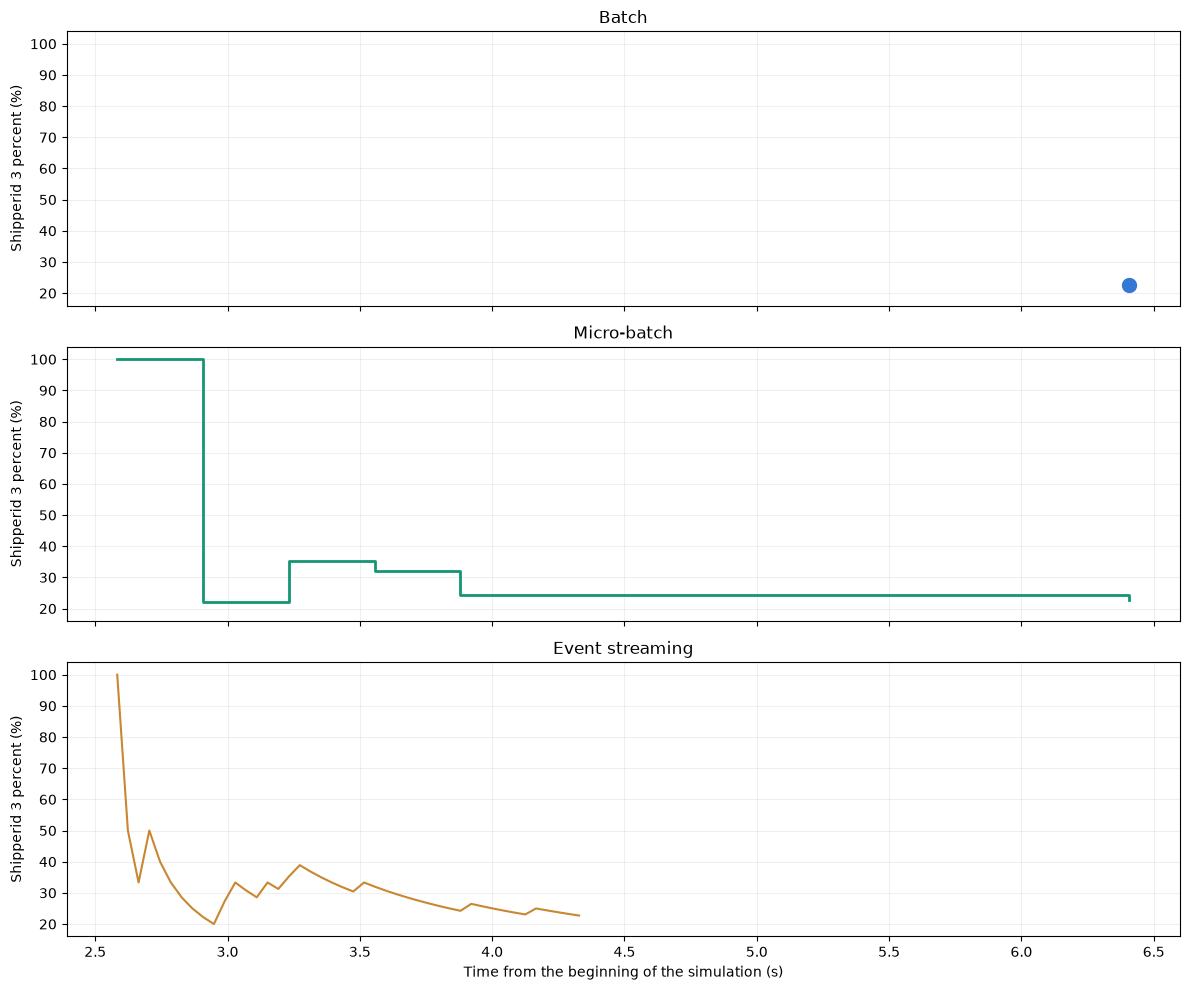

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, sharey=True)

axes[0].scatter([batch_ready_sec], [batch_percent], color="#3577d4", s=100)

axes[0].set_title("Batch")

axes[1].step([x[0] for x in micro_updates],[x[2] for x in micro_updates], where="post", color="#159572", linewidth=2)
axes[1].set_title("Micro-batch")

axes[2].plot([x[0] for x in stream_updates], [x[2] for x in stream_updates], color="#c88730", linewidth=1.5)
axes[2].set_title("Event streaming")

for ax in axes: 
    ax.set_ylabel("Shipper 3 percent (%)") 
    ax.grid(alpha=0.2)

axes[2].set_xlabel("Time from the beginning of the simulation (s)")

plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 8 – Frekvencia aktualizácií a prvý výsledok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na troch grafoch znázornite, koľkokrát sa priebežný výsledok aktualizoval. Potom vytvorte jednoduchú tabuľku, ktorá porovná <strong>čas prvého výsledku</strong>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Pri počte aktualizácií nie je vhodné zdieľať os Y: batch má jeden výsledok, streaming jeden po každej udalosti. Os X zdieľajte.</div>

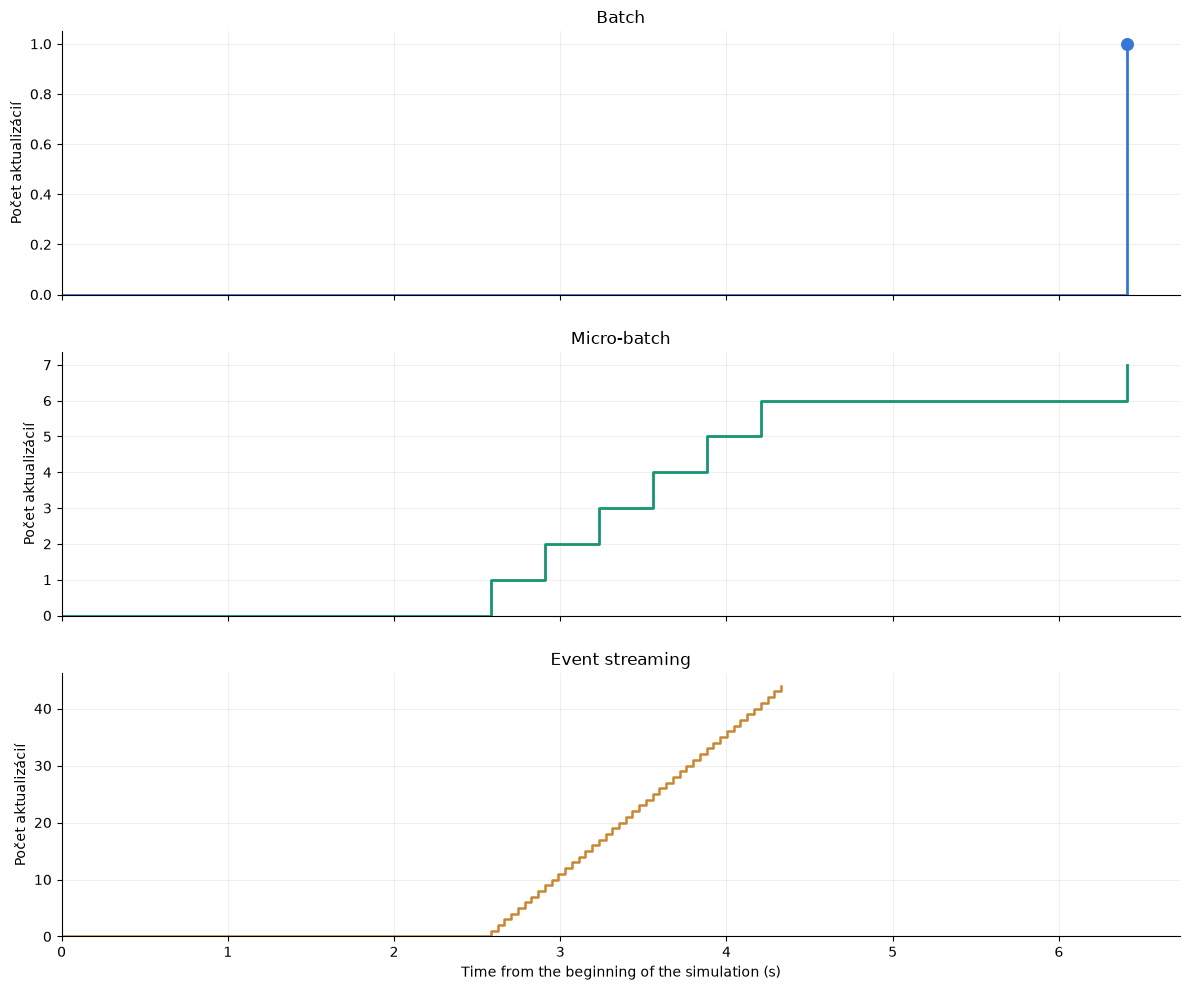

In [37]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)


axes[0].step([0, batch_ready_sec], [0, 1], where="post", color="#3577d4", linewidth=2)

axes[0].scatter([batch_ready_sec], [1], color="#3577d4", s=70, zorder=5)
axes[0].set_title("Batch")

axes[1].step([0] + [x[0] for x in micro_updates], [0] + list(range(1, len(micro_updates) + 1)), where="post", color="#159572", linewidth=2)
axes[1].set_title("Micro-batch")

axes[2].step([0] + [x[0] for x in stream_updates], [0] + list(range(1, len(stream_updates) + 1)), where="post", color="#c88730", linewidth=1.8)
axes[2].set_title("Event streaming")

for ax in axes:
    ax.set_ylabel("Počet aktualizácií")
    ax.grid(alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)

axes[2].set_xlabel("Time from the beginning of the simulation (s)")

plt.tight_layout(h_pad=2)
plt.show()


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">
  📘 Kontrola Git repozitára po 8. týždni
</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Po dokončení všetkých úloh z 8. týždňa skontrolujte, či máte vo svojom Git
  repozitári vytvorenú samostatnú vetvu
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  a či sa v nej nachádza vypracovaný notebook vytvorený počas cvičenia.
</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Obsah vetvy
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  by mal mať približne nasledujúcu štruktúru:
</p>
<pre style="background: #f9fafb; color: #111827; padding: 14px; border-radius: 7px; overflow: auto; font-size: 13px; line-height: 1.7; font-family: ui-monospace, SFMono-Regular, Menlo, monospace;">week-08
│
├── ratings.csv
├── orders.csv
│
├── batch_streaming.ipynb
└── batch_streaming_orders.ipynb
</pre>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #eab308; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">
  ⚠️ <strong>Kontrola GitHubu:</strong> Skontrolujte, či sa všetky uvedené súbory
  nachádzajú aj vo vzdialenom repozitári na GitHube. Ak ich vidíte iba lokálne
  vo VS Code, zmeny ešte neboli úspešne odoslané pomocou
  <strong>commit</strong> a <strong>push</strong>.
</div>